# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NETID = 'claym2'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

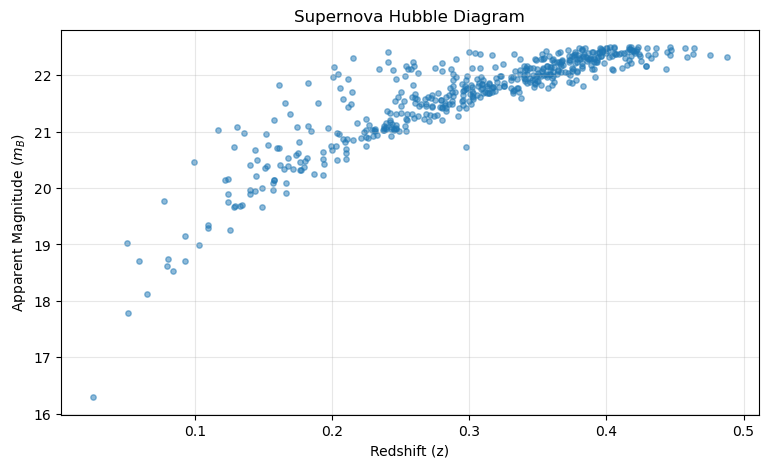

In [2]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.scatter(z, m, alpha=0.5, s=15)

plt.xlabel("Redshift (z)")
plt.ylabel("Apparent Magnitude ($m_B$)")
plt.title("Supernova Hubble Diagram")
plt.grid(alpha=0.3)

plt.show()

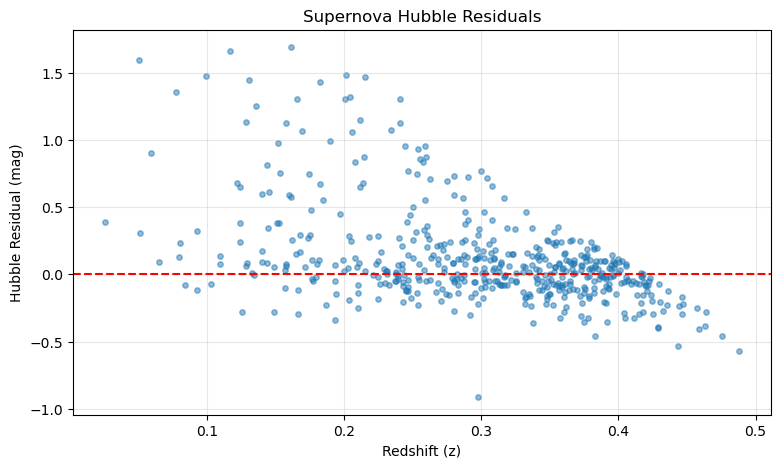

In [4]:
from astropy.cosmology import FlatLambdaCDM

cosmo = FlatLambdaCDM(H0=70, Om0=0.3)
mu = cosmo.distmod(z).value
residuals = m - (-19.30) - mu

plt.figure(figsize=(9, 5))

plt.scatter(z, residuals, alpha=0.5, s=15)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel("Redshift (z)")
plt.ylabel("Hubble Residual (mag)")
plt.title("Supernova Hubble Residuals")
plt.grid(alpha=0.3)

plt.show()

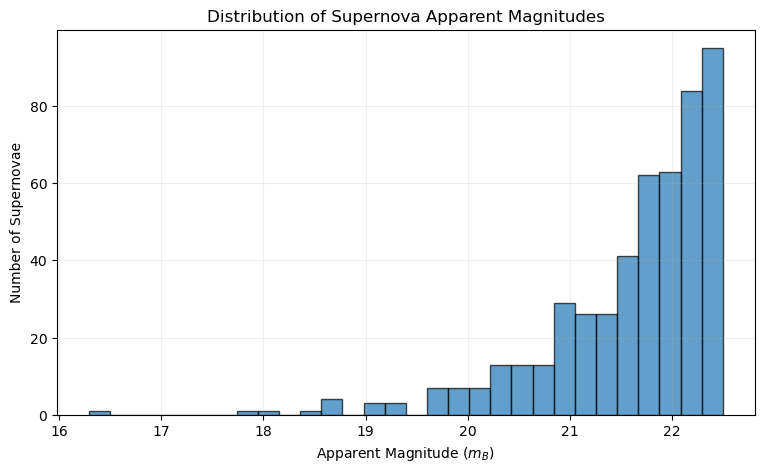

In [5]:
plt.figure(figsize=(9, 5))

plt.hist(m, bins=30, edgecolor='black', alpha=0.7)

plt.xlabel("Apparent Magnitude ($m_B$)")
plt.ylabel("Number of Supernovae")
plt.title("Distribution of Supernova Apparent Magnitudes")
plt.grid(alpha=0.2)

plt.show()

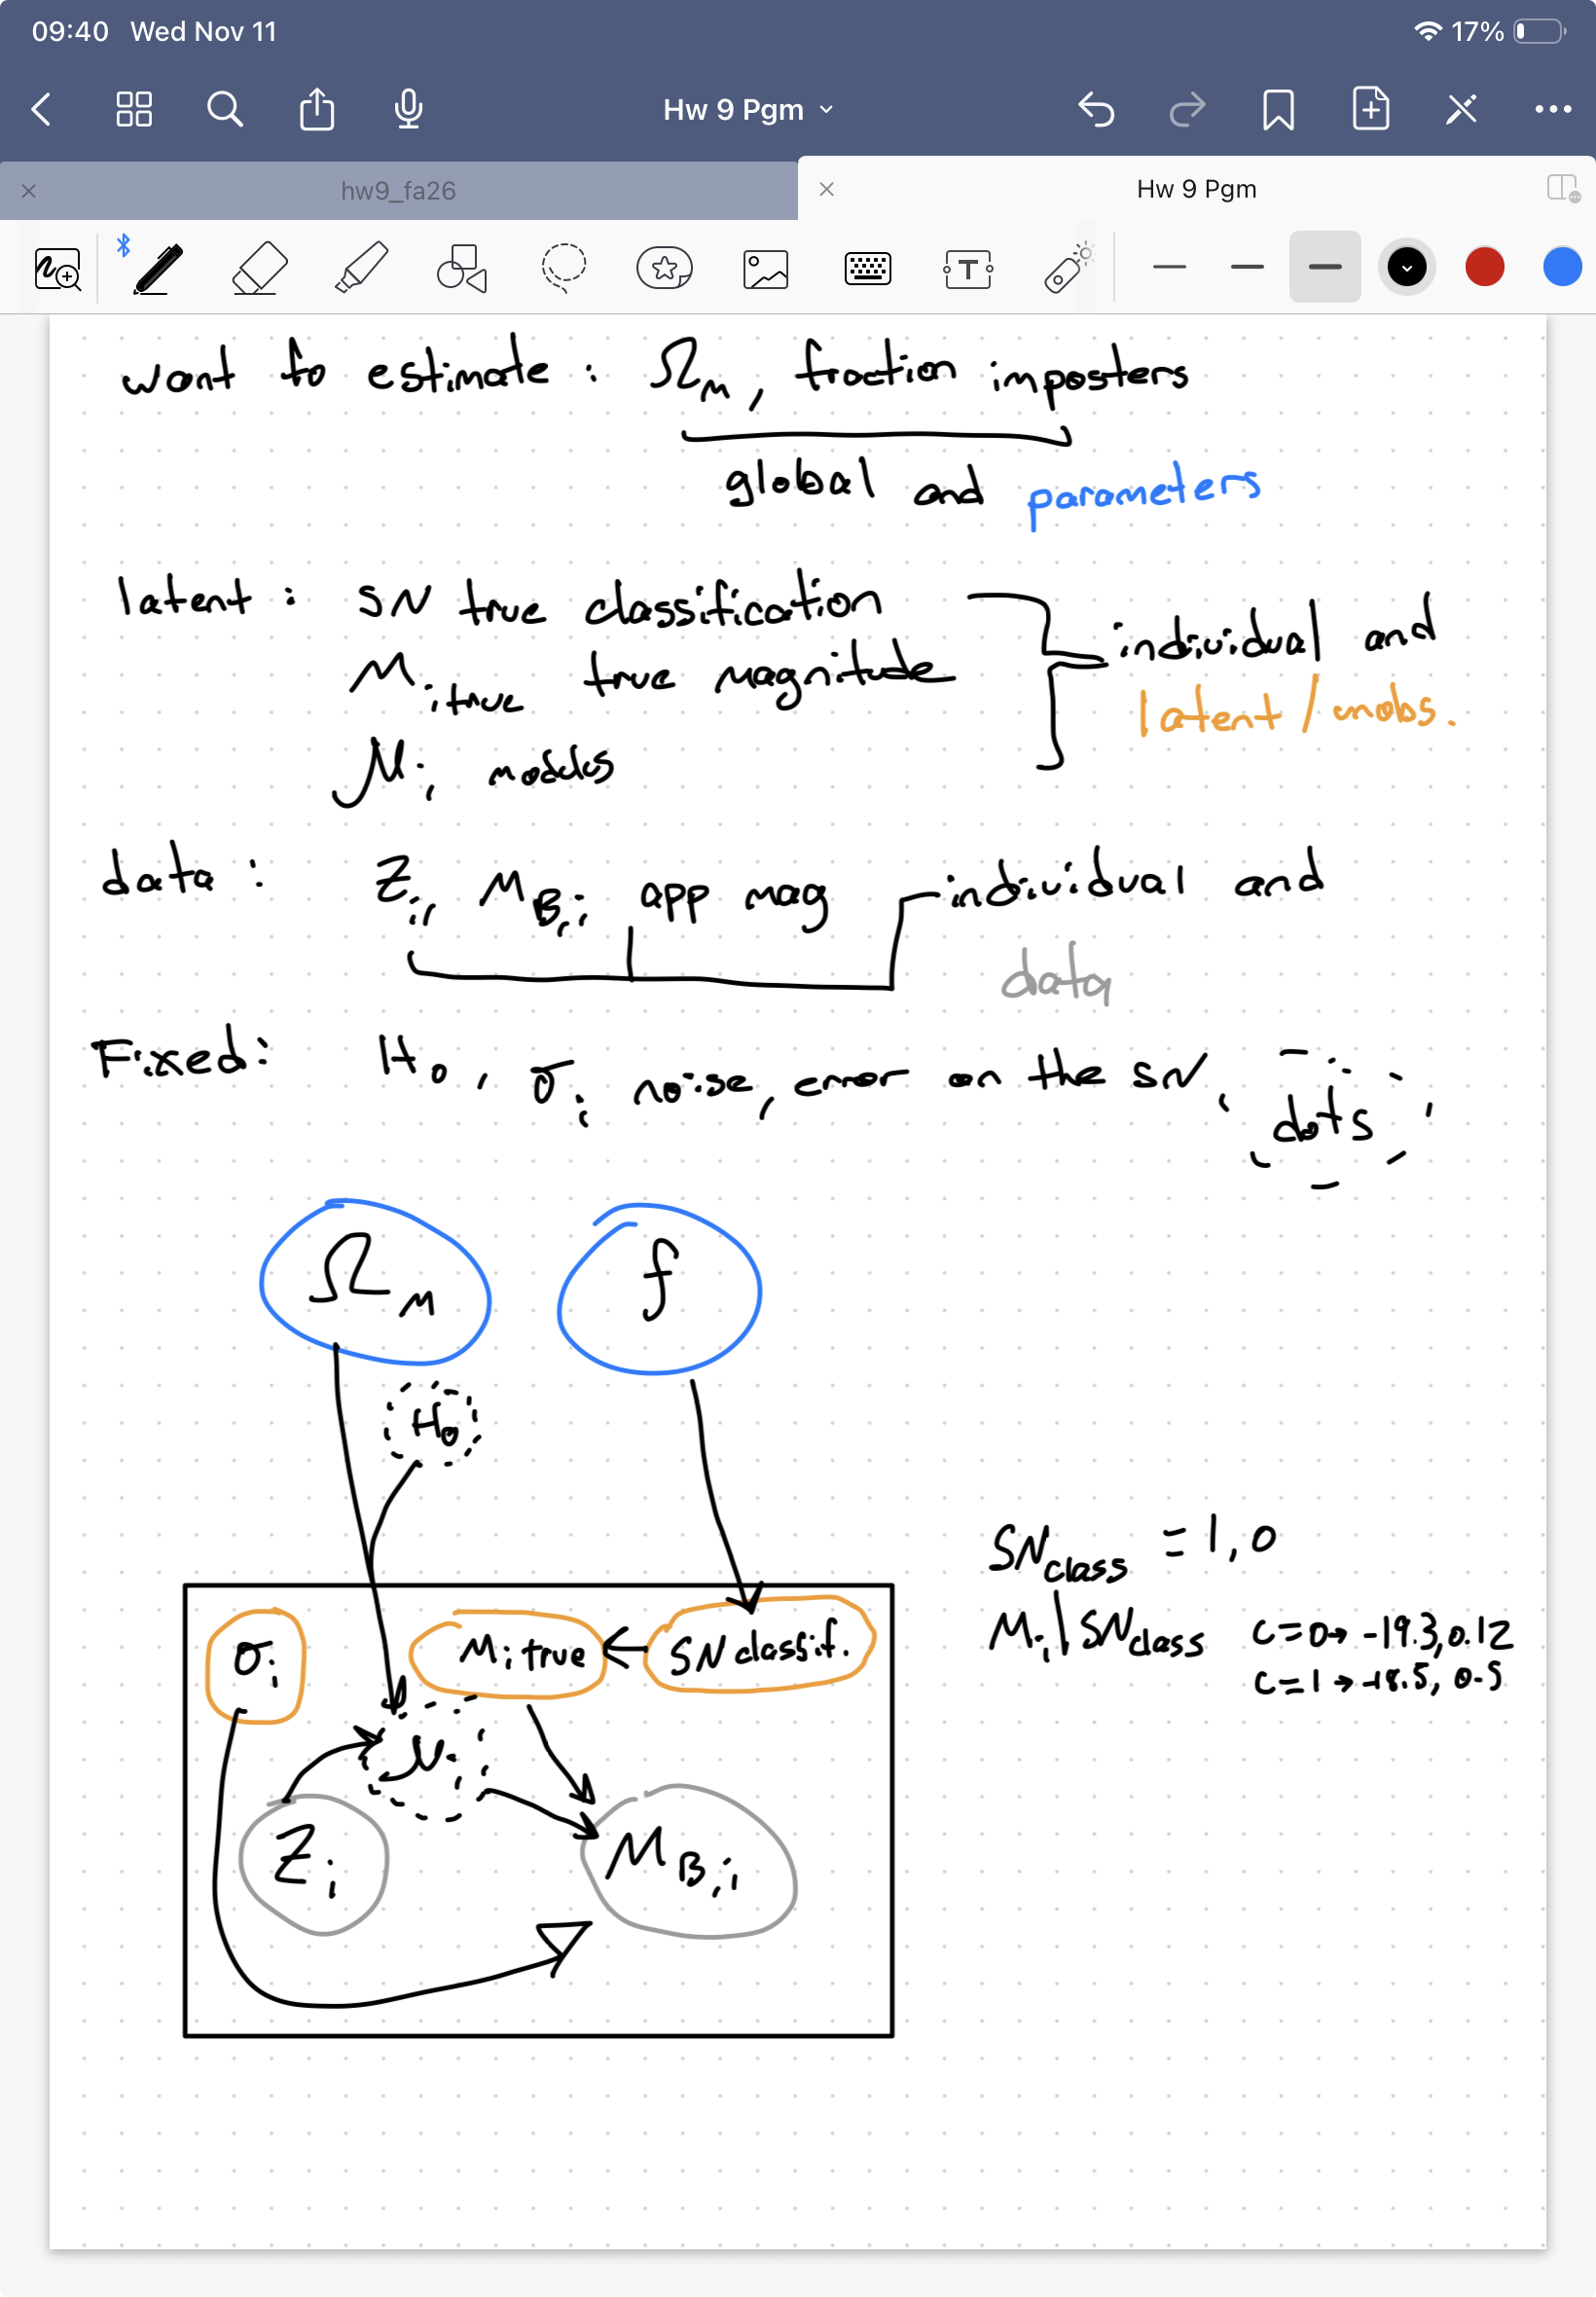

In [8]:
from astropy.cosmology import FlatLambdaCDM
from scipy.interpolate import RegularGridInterpolator

Om_grid = np.arange(0.05, 0.951, 0.005)
z_grid = np.linspace(0.01, 0.7, 1000)

mu_grid = np.zeros((len(Om_grid), len(z_grid)))

for i, Om in enumerate(Om_grid):
    cosmo = FlatLambdaCDM(H0=70, Om0=Om)
    mu_grid[i, :] = cosmo.distmod(z_grid).value

mu_interp = RegularGridInterpolator(
    (Om_grid, z_grid),
    mu_grid,
    bounds_error=False,
    fill_value=None
)

test_Om = 0.3
test_z = np.array([0.05, 0.2, 0.4, 0.65])

interpolated = mu_interp(
    np.column_stack([
        np.full(len(test_z), test_Om),
        test_z
    ])
)

cosmo = FlatLambdaCDM(H0=70, Om0=test_Om)
astropy_values = cosmo.distmod(test_z).value

print("Interpolated:", interpolated)
print("Astropy:", astropy_values)
print("Difference:", interpolated - astropy_values)

Interpolated: [36.73457378 39.95627974 41.68446293 42.9503933 ]
Astropy: [36.73459039 39.9562808  41.68446373 42.95039364]
Difference: [-1.66184315e-05 -1.05858913e-06 -8.00101802e-07 -3.37745838e-07]


In [9]:
def simulate(Om, f, rng):

    N = 500

    # 1. Generate redshifts from p(z) proportional to z^2
    u = rng.uniform(0, 1, N)

    z_sim = (
        0.01**3 + u * (0.7**3 - 0.01**3)
    )**(1/3)

    # 2. Determine which supernovae are impostors
    is_impostor = rng.binomial(1, f, N)

    # 3. Generate absolute magnitudes
    M = np.where(
        is_impostor == 1,
        rng.normal(-18.5, 0.5, N),
        rng.normal(-19.30, 0.12, N)
    )

    # 4. Calculate distance modulus
    mu_sim = mu_interp(
        np.column_stack([
            np.full(N, Om),
            z_sim
        ])
    )

    # 5. Generate measurement errors
    epsilon = rng.normal(0, 0.10, N)

    # 6. Calculate apparent magnitude
    m_sim = M + mu_sim + epsilon

    return z_sim, m_sim

In [10]:
rng = np.random.default_rng(42)

z_sim, m_sim = simulate(0.3, 0.1, rng)

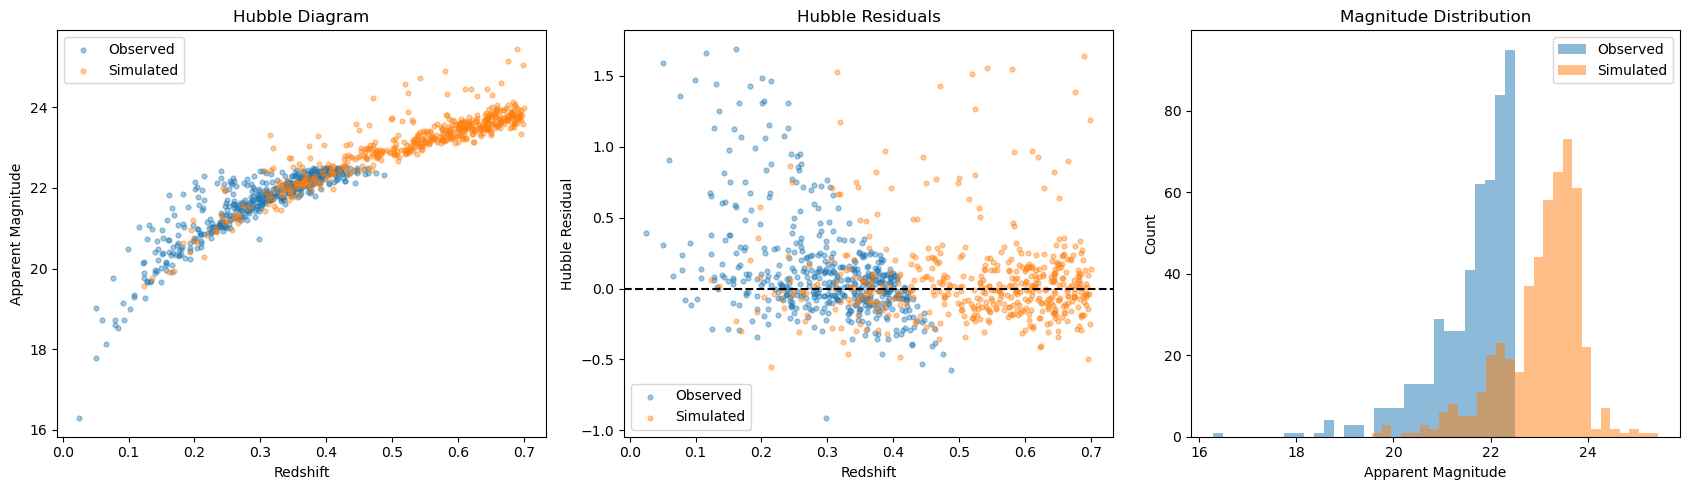

In [11]:
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

mu_data = cosmo.distmod(z).value
mu_sim = cosmo.distmod(z_sim).value

residual_data = m - (-19.30) - mu_data
residual_sim = m_sim - (-19.30) - mu_sim

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Hubble diagram
axes[0].scatter(z, m, alpha=0.4, s=12, label="Observed")
axes[0].scatter(z_sim, m_sim, alpha=0.4, s=12, label="Simulated")
axes[0].set_xlabel("Redshift")
axes[0].set_ylabel("Apparent Magnitude")
axes[0].set_title("Hubble Diagram")
axes[0].legend()

# Residuals
axes[1].scatter(z, residual_data, alpha=0.4, s=12, label="Observed")
axes[1].scatter(z_sim, residual_sim, alpha=0.4, s=12, label="Simulated")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Redshift")
axes[1].set_ylabel("Hubble Residual")
axes[1].set_title("Hubble Residuals")
axes[1].legend()

# Histogram
axes[2].hist(m, bins=30, alpha=0.5, label="Observed")
axes[2].hist(m_sim, bins=30, alpha=0.5, label="Simulated")
axes[2].set_xlabel("Apparent Magnitude")
axes[2].set_ylabel("Count")
axes[2].set_title("Magnitude Distribution")
axes[2].legend()

plt.tight_layout()
plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

There doesn't appear to be anything too crazy in the scatterplot at the top besides a pretty decent low residual spread at the smaller redshifts that could indicate the imposter calculations. It might be possible that the impostors have a fainted absolute magnitude leading to positive residuals. The entire graph is trending downwards, meaning as z increases, some value(s) in our equation could be pulling the residuals more negative.

The histogram is also looking pretty alright, with no obvious secondary populations. This isn't a perfectly Gaussian distribution and we have a few bright stars below 20 mags. Since there are only a few below, I don't think I would flag those immediately. I think the most interesting thing is the fact it is not Gaussian, meaning Ia SN could be set in a specific range of mag.

The simulator, however, simulates the data to be a good step off from the actual data. There is definitely something skewing the current data. The Diagram predicts an overall greater redshift and magnitude while increasing the redshift in the residual plot. Lastly, the magnitude distribution calls for a slightly more Gaussian-distributed plot with virtually not magnitudes lower than 19.

The simulator builds a distance modulus lookup of possible values, interpolates between the grid points, allowing for a fast approximate for the modulus within the grid. It checks against Astropy, where we can see extremely small differences. It utilizes guesses of 0.3 omega and 0.1 mag on random numbers.

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

In [14]:
from astropy.cosmology import FlatLambdaCDM
from scipy.optimize import minimize_scalar
import numpy as np

sigma_tot = np.sqrt(0.12**2 + 0.10**2)

def chi_squared(Om):

    cosmo = FlatLambdaCDM(H0=70, Om0=Om)

    mu = cosmo.distmod(z).value

    residuals = m - (-19.30) - mu

    chi2 = np.sum(residuals**2 / sigma_tot**2)

    return chi2

result = minimize_scalar(
    chi_squared,
    bounds=(0.001, 0.999),
    method='bounded'
)

Om_best = result.x
chi2_min = result.fun

print("Best-fit Omega_m:", Om_best)
print("Minimum chi-squared:", chi2_min)

Best-fit Omega_m: 0.18008064966703494
Minimum chi-squared: 2933.9642450892397


Omega_m = 0.1801 +/- 0.0127
68% interval: [0.1674, 0.1929]


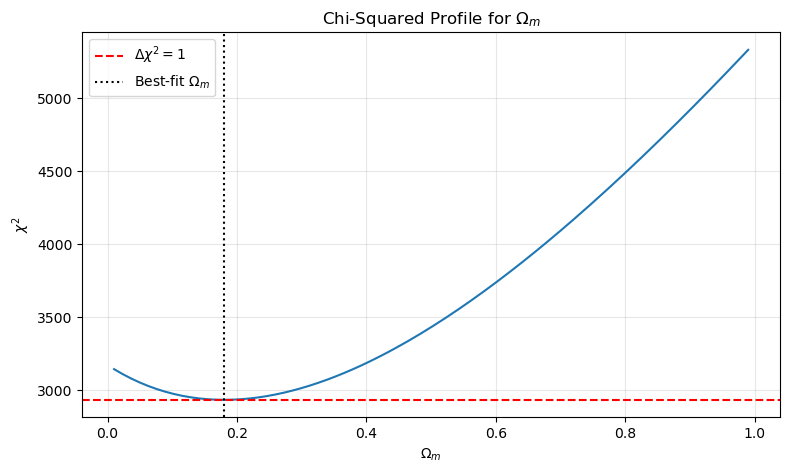

In [15]:
from scipy.optimize import brentq

target = chi2_min + 1

Om_lower = brentq(
    lambda Om: chi_squared(Om) - target,
    0.001,
    Om_best
)

Om_upper = brentq(
    lambda Om: chi_squared(Om) - target,
    Om_best,
    0.999
)

# Calculate the 1-sigma error
Om_error = (Om_upper - Om_lower) / 2

print(f"Omega_m = {Om_best:.4f} +/- {Om_error:.4f}")
print(f"68% interval: [{Om_lower:.4f}, {Om_upper:.4f}]")


Om_values = np.linspace(0.01, 0.99, 150)

chi2_values = [chi_squared(Om) for Om in Om_values]

plt.figure(figsize=(9, 5))

plt.plot(Om_values, chi2_values)

plt.axhline(chi2_min + 1, color='red', linestyle='--',
            label=r'$\Delta\chi^2=1$')

plt.axvline(Om_best, color='black', linestyle=':',
            label=r'Best-fit $\Omega_m$')

plt.xlabel(r'$\Omega_m$')
plt.ylabel(r'$\chi^2$')
plt.title(r'Chi-Squared Profile for $\Omega_m$')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**ANSWER (the naive fit, then why the impostors push it the way they do):**

When we incorrectly assumed the T1a, the model interpreted the faintness as evidence that they are further away than they really are, predicting at larger distances and the impostors biased omega down. The imposters are slightly fainter than the T1a, coming in at about -18.5 mean magnitude rather than -19.30, larger distances, and lower omega_m leading to a downward bias.

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

The first summary statistic will be the median residual that I expect to track omega. I will pick this statistic becuase changing omega shifts the distance modulus and therefore, the diagram.

The second statistic will be the fraction of resiuals above a certain threshold. This will track the impostors as those are the fainter of the groups. A large fraction would increase the number of objects in a positive-residual tail created from those fainter imposters.

In [16]:
# Calculate the reference distance modulus at Omega_m = 0.3
mu_reference = FlatLambdaCDM(
    H0=70,
    Om0=0.3
).distmod(z).value

# Hubble residuals
residuals = m - (-19.30) - mu_reference

# Summary 1: median residual
observed_median = np.median(residuals)

# Summary 2: fraction of residuals above +0.5 mag
observed_tail_fraction = np.mean(residuals > 0.5)

observed_summaries = np.array([
    observed_median,
    observed_tail_fraction
])

print("Observed median residual:", observed_median)
print("Observed positive-tail fraction:", observed_tail_fraction)

Observed median residual: 0.04046573970099132
Observed positive-tail fraction: 0.116


In [17]:
def simulate_summaries(Om, f, rng):
    N = len(z)

    # Decide which supernovae are impostors
    is_impostor = rng.binomial(1, f, N)

    # Draw absolute magnitudes from the appropriate population
    M = np.where(
        is_impostor == 1,
        rng.normal(-18.5, 0.5, N),
        rng.normal(-19.30, 0.12, N)
    )

    # Calculate distance modulus for this Omega_m
    mu = mu_interp(
        np.column_stack([
            np.full(N, Om),
            z
        ])
    )

    # Add measurement noise
    epsilon = rng.normal(0, 0.10, N)

    # Simulated apparent magnitudes
    m_sim = M + mu + epsilon

    # Residuals relative to the same reference cosmology
    r_sim = m_sim - (-19.30) - mu_reference

    # Calculate the two summaries
    median_residual = np.median(r_sim)
    tail_fraction = np.mean(r_sim > 0.5)

    return np.array([median_residual, tail_fraction])

In [18]:
rng = np.random.default_rng(42)

n_plot = 3000

Om_plot = rng.uniform(0.05, 0.7, n_plot)
f_plot = rng.uniform(0.0, 0.5, n_plot)

summaries_plot = np.zeros((n_plot, 2))

for i in range(n_plot):
    summaries_plot[i] = simulate_summaries(
        Om_plot[i],
        f_plot[i],
        rng
    )

median_plot = summaries_plot[:, 0]
tail_plot = summaries_plot[:, 1]

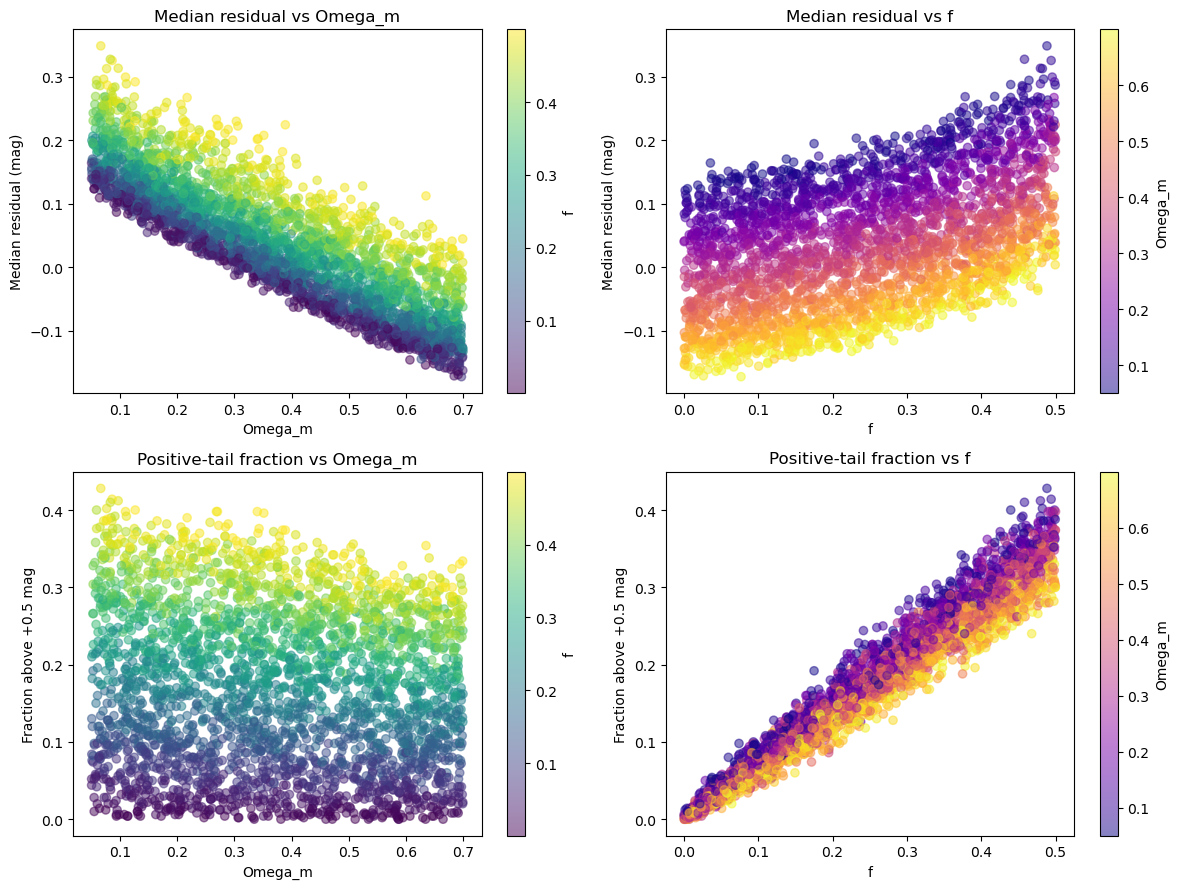

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Median residual vs Omega_m
sc = axes[0, 0].scatter(
    Om_plot, median_plot,
    c=f_plot, cmap="viridis", alpha=0.5
)
axes[0, 0].set_xlabel("Omega_m")
axes[0, 0].set_ylabel("Median residual (mag)")
axes[0, 0].set_title("Median residual vs Omega_m")
plt.colorbar(sc, ax=axes[0, 0], label="f")

# Median residual vs f
sc = axes[0, 1].scatter(
    f_plot, median_plot,
    c=Om_plot, cmap="plasma", alpha=0.5
)
axes[0, 1].set_xlabel("f")
axes[0, 1].set_ylabel("Median residual (mag)")
axes[0, 1].set_title("Median residual vs f")
plt.colorbar(sc, ax=axes[0, 1], label="Omega_m")

# Tail fraction vs Omega_m
sc = axes[1, 0].scatter(
    Om_plot, tail_plot,
    c=f_plot, cmap="viridis", alpha=0.5
)
axes[1, 0].set_xlabel("Omega_m")
axes[1, 0].set_ylabel("Fraction above +0.5 mag")
axes[1, 0].set_title("Positive-tail fraction vs Omega_m")
plt.colorbar(sc, ax=axes[1, 0], label="f")

# Tail fraction vs f
sc = axes[1, 1].scatter(
    f_plot, tail_plot,
    c=Om_plot, cmap="plasma", alpha=0.5
)
axes[1, 1].set_xlabel("f")
axes[1, 1].set_ylabel("Fraction above +0.5 mag")
axes[1, 1].set_title("Positive-tail fraction vs f")
plt.colorbar(sc, ax=axes[1, 1], label="Omega_m")

plt.tight_layout()
plt.show()

In [20]:
rng = np.random.default_rng(123)

n_sim = 50000
batch_size = 500

# Draw parameter values from the flat priors
Om_sim = rng.uniform(0.05, 0.7, n_sim)
f_sim = rng.uniform(0.0, 0.5, n_sim)

# Store the two summaries for every simulation
summaries_sim = np.zeros((n_sim, 2))

N = len(z)

for start in range(0, n_sim, batch_size):

    end = min(start + batch_size, n_sim)
    current_size = end - start

    Om_batch = Om_sim[start:end]
    f_batch = f_sim[start:end]

    # Draw impostor indicators
    is_impostor = rng.binomial(
        1,
        f_batch[:, None],
        size=(current_size, N)
    )

    # Draw absolute magnitudes
    M_Ia = rng.normal(-19.30, 0.12, (current_size, N))
    M_impostor = rng.normal(-18.5, 0.5, (current_size, N))

    M_sim = np.where(is_impostor == 1, M_impostor, M_Ia)

    # Calculate distance modulus for each simulated Omega_m
    Om_values = np.repeat(Om_batch, N)
    z_values = np.tile(z, current_size)

    mu_sim = mu_interp(
        np.column_stack([Om_values, z_values])
    ).reshape(current_size, N)

    # Add measurement noise
    epsilon = rng.normal(0, 0.10, (current_size, N))

    # Generate apparent magnitudes
    m_sim = M_sim + mu_sim + epsilon

    # Calculate residuals relative to Omega_m = 0.3
    r_sim = m_sim - (-19.30) - mu_reference

    # Summary 1: median residual
    median_residual = np.median(r_sim, axis=1)

    # Summary 2: positive-tail fraction
    tail_fraction = np.mean(r_sim > 0.5, axis=1)

    summaries_sim[start:end, 0] = median_residual
    summaries_sim[start:end, 1] = tail_fraction

print("Finished simulations:", n_sim)

Finished simulations: 50000


In [21]:
np.savez(
    "abc_simulations.npz",
    Om_sim=Om_sim,
    f_sim=f_sim,
    summaries_sim=summaries_sim,
    observed_summaries=observed_summaries
)

In [22]:
# Standard deviation of each summary across the simulations
summary_scales = np.std(summaries_sim, axis=0)

# Standardized Euclidean distance from the observed summaries
distances = np.sqrt(
    np.sum(
        ((summaries_sim - observed_summaries) / summary_scales)**2,
        axis=1
    )
)

# Two tolerances: accept the closest 5% and closest 1%
epsilon_large = np.quantile(distances, 0.05)
epsilon_small = np.quantile(distances, 0.01)

print("Large epsilon:", epsilon_large)
print("Small epsilon:", epsilon_small)

Large epsilon: 0.4015144722411994
Small epsilon: 0.17914878341181242


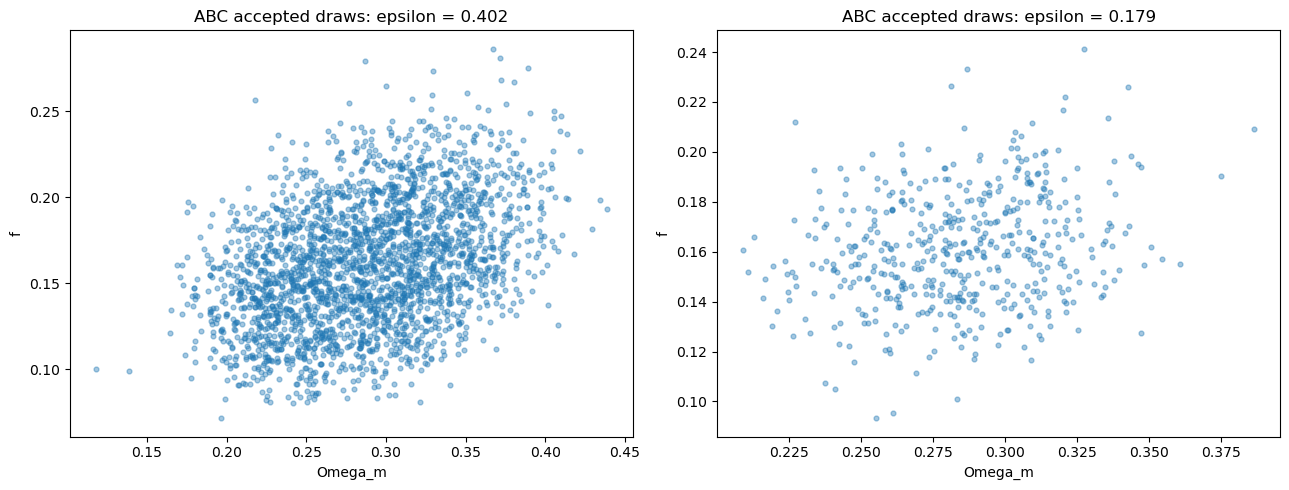

Accepted at large epsilon: 2500
Accepted at small epsilon: 500


In [23]:
accepted_large = distances <= epsilon_large
accepted_small = distances <= epsilon_small

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    Om_sim[accepted_large],
    f_sim[accepted_large],
    alpha=0.4,
    s=12
)
axes[0].set_xlabel("Omega_m")
axes[0].set_ylabel("f")
axes[0].set_title(f"ABC accepted draws: epsilon = {epsilon_large:.3f}")

axes[1].scatter(
    Om_sim[accepted_small],
    f_sim[accepted_small],
    alpha=0.4,
    s=12
)
axes[1].set_xlabel("Omega_m")
axes[1].set_ylabel("f")
axes[1].set_title(f"ABC accepted draws: epsilon = {epsilon_small:.3f}")

plt.tight_layout()
plt.show()

print("Accepted at large epsilon:", np.sum(accepted_large))
print("Accepted at small epsilon:", np.sum(accepted_small))

In [24]:
# Use the smaller tolerance as the initial final choice
final_accepted = accepted_small

Om_posterior = Om_sim[final_accepted]
f_posterior = f_sim[final_accepted]

# Omega_m posterior statistics
Om_median = np.median(Om_posterior)
Om_lower, Om_upper = np.percentile(
    Om_posterior, [2.5, 97.5]
)

# f posterior statistics
f_median = np.median(f_posterior)
f_lower, f_upper = np.percentile(
    f_posterior, [2.5, 97.5]
)

print("Omega_m posterior:")
print("Median:", Om_median)
print("95% interval:", Om_lower, Om_upper)

print("\nf posterior:")
print("Median:", f_median)
print("95% interval:", f_lower, f_upper)

Omega_m posterior:
Median: 0.2844239192468455
95% interval: 0.2264367483820664 0.3406822977545126

f posterior:
Median: 0.1600833607343173
95% interval: 0.12057498650684158 0.20557321111831914


**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

The median resisual ends up decreasing as omega increases and increases as the fraction increases, less directly as omega, though. Changing omega shifts the predicted distance as expected, while increasing the fraction adds more faint objects.

The fraction above 0.5 magnitude increases strongly with the fraction and its comparison with omega is weak. The increasing the impostor fraction increases the amount of objects that are fainter than the T1a population. The graphs do show that the median residual partially tracks omega and that the tail tracks the fraction of imposters. 

Matter density parameter - 0.28844 95% [0.2264, 0.3407]
Impostor Fraction - 0.1601 95% [0.1206, 0.2056]

I used summary statistics ccalculated from the Hubble residuals relative to omega = 0.3. The median residual and the fractoin of supernovae greater than 0.5 mag. I expected the residual to track omega, since changing matter densirt changes distances and shifts the diagram. I also expected the fractoin to track the imposter fraction since the imposters have a fainter mean magnitude than the T1a supernovae. The fraction and residual increase strongly with f. In the ABC, there were 50,000 parameters from the flat priors of omega including 0.05, 0.7 and f along the same bounds. I simulated the dataset at the redshifts and standardized each difference by the standard deviation across the prior simulations. I then calculated the Euclidian distance.

I looked at epsilon 0.402 accepting 2500 simulations while epsilon 0.179 acceptem 500 simulations. The smaller rolerance produced a more concentrated acceptance in the omega_m region. The accepted coints were spread and not against the prior bounds, indicating that they are not forced by the limits. 

I used the smaller tolerance, the median for omega was 0.2844, with a 95% interval of [0.2264, 0.3407]. The posterior median for the imposter was 0.1601 with a 95% interval of [0.1206, 0.2056].

The ABC estimate of omega is higher than the original estimate of 0.1801. We assumed all supernovae to be T1a so faint imposteres were likely seen as distant objects. This biased the fit toward a lower value of omega. By not doing that, ABC is allowed to look for the biased faintness.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

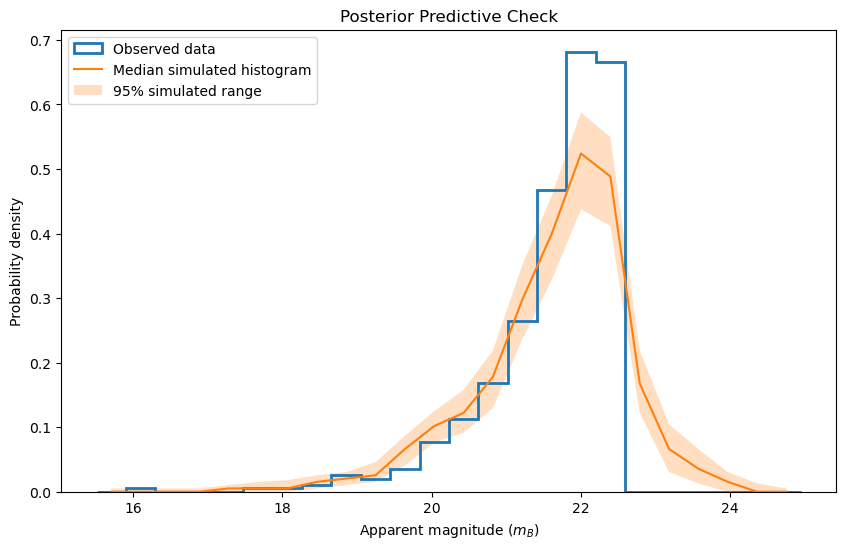

In [28]:
def simulate_dataset(Om, f, rng):
    N = len(z)

    # Decide which objects are impostors
    is_impostor = rng.binomial(1, f, N)

    # Draw absolute magnitudes
    M_Ia = rng.normal(-19.30, 0.12, N)
    M_impostor = rng.normal(-18.5, 0.5, N)

    M = np.where(is_impostor == 1, M_impostor, M_Ia)

    # Calculate distance modulus
    mu = mu_interp(
        np.column_stack([
            np.full(N, Om),
            z
        ])
    )

    # Add measurement noise
    epsilon = rng.normal(0, 0.10, N)

    return M + mu + epsilon


rng = np.random.default_rng(456)

# Randomly select 100 accepted parameter draws
accepted_indices = np.where(final_accepted)[0]

selected_indices = rng.choice(
    accepted_indices,
    size=100,
    replace=False
)

# Simulate 100 datasets
ppc_datasets = []

for index in selected_indices:
    Om = Om_sim[index]
    f = f_sim[index]

    simulated_magnitudes = simulate_dataset(Om, f, rng)

    ppc_datasets.append(simulated_magnitudes)

ppc_datasets = np.array(ppc_datasets)



# Use the same bins for every histogram
bins = np.linspace(
    min(m.min(), ppc_datasets.min()),
    max(m.max(), ppc_datasets.max()),
    25
)

# Real data histogram
observed_hist, bin_edges = np.histogram(
    m,
    bins=bins,
    density=True
)

# Histograms for all simulated datasets
simulated_histograms = []

for dataset in ppc_datasets:
    hist, _ = np.histogram(
        dataset,
        bins=bins,
        density=True
    )
    simulated_histograms.append(hist)

simulated_histograms = np.array(simulated_histograms)

# Calculate median and 95% predictive range for each bin
hist_median = np.median(simulated_histograms, axis=0)

hist_lower = np.percentile(
    simulated_histograms, 2.5, axis=0
)

hist_upper = np.percentile(
    simulated_histograms, 97.5, axis=0
)

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Plot
plt.figure(figsize=(10, 6))

plt.hist(
    m,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="Observed data"
)

plt.plot(
    bin_centers,
    hist_median,
    label="Median simulated histogram"
)

plt.fill_between(
    bin_centers,
    hist_lower,
    hist_upper,
    alpha=0.25,
    label="95% simulated range"
)

plt.xlabel("Apparent magnitude ($m_B$)")
plt.ylabel("Probability density")
plt.title("Posterior Predictive Check")
plt.legend()
plt.show()

The simulated 95% range and median simulated histogram lies pretty nicely within the range of the observed data, indicating that the model can reproduce the look of the data. This is just a check, not proof. 

In [29]:
rng = np.random.default_rng(789)

n_coverage = 20
n_reference = len(Om_sim) - 1

# Randomly choose 20 simulations to act as pretend datasets
test_indices = rng.choice(
    len(Om_sim),
    size=n_coverage,
    replace=False
)

Om_covered = 0
f_covered = 0

Om_intervals = []
f_intervals = []

for test_index in test_indices:

    # Known true parameters for this pretend dataset
    true_Om = Om_sim[test_index]
    true_f = f_sim[test_index]

    # Its summaries act as the observed summaries
    pretend_observed = summaries_sim[test_index]

    # Use every simulation except the pretend observation
    reference_mask = np.ones(len(Om_sim), dtype=bool)
    reference_mask[test_index] = False

    reference_Om = Om_sim[reference_mask]
    reference_f = f_sim[reference_mask]
    reference_summaries = summaries_sim[reference_mask]

    # Standardize using the reference simulations
    scales = np.std(reference_summaries, axis=0)

    distances = np.sqrt(
        np.sum(
            ((reference_summaries - pretend_observed) / scales)**2,
            axis=1
        )
    )

    # Accept the closest 1% (same rule as final ABC)
    epsilon = np.quantile(distances, 0.01)
    accepted = distances <= epsilon

    # Calculate 95% intervals
    Om_interval = np.percentile(
        reference_Om[accepted],
        [2.5, 97.5]
    )

    f_interval = np.percentile(
        reference_f[accepted],
        [2.5, 97.5]
    )

    Om_intervals.append(Om_interval)
    f_intervals.append(f_interval)

    # Check whether the known truths fall inside the intervals
    if Om_interval[0] <= true_Om <= Om_interval[1]:
        Om_covered += 1

    if f_interval[0] <= true_f <= f_interval[1]:
        f_covered += 1

    print(
        f"Test {len(Om_intervals):2d}: "
        f"true Om={true_Om:.3f}, "
        f"interval=[{Om_interval[0]:.3f}, {Om_interval[1]:.3f}], "
        f"true f={true_f:.3f}, "
        f"interval=[{f_interval[0]:.3f}, {f_interval[1]:.3f}]"
    )

# Calculate empirical coverage
Om_coverage = Om_covered / n_coverage
f_coverage = f_covered / n_coverage

print("\nCoverage results")
print(f"Omega_m: {Om_covered}/{n_coverage} = {Om_coverage:.1%}")
print(f"f:       {f_covered}/{n_coverage} = {f_coverage:.1%}")

Test  1: true Om=0.348, interval=[0.300, 0.458], true f=0.306, interval=[0.246, 0.372]
Test  2: true Om=0.336, interval=[0.223, 0.353], true f=0.237, interval=[0.184, 0.293]
Test  3: true Om=0.640, interval=[0.579, 0.696], true f=0.012, interval=[0.001, 0.052]
Test  4: true Om=0.182, interval=[0.111, 0.228], true f=0.215, interval=[0.191, 0.296]
Test  5: true Om=0.429, interval=[0.335, 0.485], true f=0.298, interval=[0.243, 0.364]
Test  6: true Om=0.152, interval=[0.099, 0.211], true f=0.149, interval=[0.107, 0.190]
Test  7: true Om=0.630, interval=[0.563, 0.696], true f=0.215, interval=[0.188, 0.298]
Test  8: true Om=0.395, interval=[0.353, 0.460], true f=0.046, interval=[0.024, 0.091]
Test  9: true Om=0.385, interval=[0.222, 0.467], true f=0.471, interval=[0.420, 0.499]
Test 10: true Om=0.449, interval=[0.422, 0.534], true f=0.014, interval=[0.002, 0.054]
Test 11: true Om=0.567, interval=[0.534, 0.682], true f=0.192, interval=[0.156, 0.268]
Test 12: true Om=0.501, interval=[0.310, 0.

**ANSWER (the check, the coverage, and the assumption):**

below

Picking 20/50,000 simulations, pretending each one is an observed dataset, hiding its true parameters, using 49,999 as a reference, and accepting closest 1%, and calculating 95% interval check whether they contain true parameters yielded 20/20 times. 

One major assumtion that was brought to my attention was the fact that this survey collected data on every supernova regardless of the intensity. Usually, there is likely some kind of limit, as seen in previous labs that does not allow for the selected population to be observed. Issues arise in the higher redshifts, resulting in those ones being less likely to get observed. It has a great selection effect where the most greatly redshifted objects are not seen, giving the sample a brighter look.

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

I used ChatGPT to run graphs, simulations, models, and model setup for this lab. 
**REFLECTION:**

The biggest issue with this lab was the fact that the survery was open to supernovae of all intensity, often leading to a selection effect where redshifts of greater magnitude were left out from the data. In the end result, much of the dataset looked brighter due to fewer faint observations. Since all types of supernovae were allowed in the observations because of this, the brightest core-collapse SNs (that looked like T1a), were mistaken for T1a because they were brighter, yet more distant, appearing to be T1as. If we pretended all observations were T1a, the distance modulus messed with omega as now discrepancies were showing. 

Without checking the output of the ABC posterior and imposter calculation, there was a potential for the data to be marked as clean and fainter supernovae treated as evidence for larger distances and not as imposter core-collapse novae. Another interesting check would have been to check if the accepted simulations were not up against a prior boundary, indicating that something else could be present in the data.
**VERIFICATION PLAN:**

1. Parameter recovery test is a great way to see if the varidation occurs, Genrating a simulated dataset with known omega and f values and attempting to recover them. A failure with this would have been the values recovered that differed from the inputs or excluded the known values from intervals.
2. Additional coverage tests, repeating ABC using simulated datasets with known parameters to deteect how often a 95% credible interval contained the true omega and f. The intervals should contain the true values around 95% of the time. A lower percentage would suggest that the posterior intervals are too narrow or some bias is present in ABC.
3. I looked at distributions around two values of epsilion. I checked whether accepted draws grouped near the edges of the prior. Large groups at the boundary would suggest that the prior limits might be moving the results rather than data.



Holding f constant and changing omega first, then holding omega constant and checking f is a good way to see what happens. If you increase omega, the median residual should decrease and holding f constant should increase the fraction.

In [30]:
rng = np.random.default_rng(42)

# Change Omega_m while holding f constant
for Om in [0.1, 0.3, 0.5, 0.7]:
    summaries = simulate_summaries(Om, 0.15, rng)
    print("Omega_m:", Om, "Summaries:", summaries)

print()

# Change f while holding Omega_m constant
for f_value in [0.0, 0.1, 0.2, 0.3, 0.4]:
    summaries = simulate_summaries(0.3, f_value, rng)
    print("f:", f_value, "Summaries:", summaries)

Omega_m: 0.1 Summaries: [0.12339229 0.108     ]
Omega_m: 0.3 Summaries: [0.03307833 0.116     ]
Omega_m: 0.5 Summaries: [-0.05016557  0.088     ]
Omega_m: 0.7 Summaries: [-0.14820675  0.08      ]

f: 0.0 Summaries: [-0.0086727  0.002    ]
f: 0.1 Summaries: [0.02053955 0.074     ]
f: 0.2 Summaries: [0.01653848 0.122     ]
f: 0.3 Summaries: [0.11231579 0.254     ]
f: 0.4 Summaries: [0.15716022 0.326     ]


That pattern is observed.